Part 1 — Import libraries and understand the data

Step 1: Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("Dataset.csv")

Step 2: View the first five rows

In [3]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


Step 3: Check rows and columns

In [4]:
df.shape

(17379, 17)

Step 4: Check column names

In [5]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

Step 5: Check data types

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   instant     17379 non-null  int64
 1   dteday      17379 non-null  str  
 2   season      17379 non-null  str  
 3   yr          17379 non-null  str  
 4   mnth        17379 non-null  str  
 5   hr          17379 non-null  int64
 6   holiday     17379 non-null  str  
 7   weekday     17379 non-null  int64
 8   workingday  17379 non-null  str  
 9   weathersit  17379 non-null  str  
 10  temp        17379 non-null  str  
 11  atemp       17379 non-null  str  
 12  hum         17379 non-null  str  
 13  windspeed   17379 non-null  str  
 14  casual      17379 non-null  str  
 15  registered  17379 non-null  str  
 16  cnt         17379 non-null  int64
dtypes: int64(4), str(13)
memory usage: 3.3 MB


Step 6: Check missing values and duplicates

In [7]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

Step 7: View summary statistics

In [9]:
df.describe()

,instant,hr,weekday,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000
mean,8690.0000,11.546752,3.003683,189.463088
std,5017.0295,6.914405,2.005771,181.387599
min,1.0000,0.000000,0.000000,1.000000
25%,4345.5000,6.000000,1.000000,40.000000
50%,8690.0000,12.000000,3.000000,142.000000
75%,13034.5000,18.000000,5.000000,281.000000
max,17379.0000,23.000000,6.000000,977.000000


Part 2 — Data cleaning

Step 8: Replace question marks

In [10]:
df = df.replace("?", pd.NA)

Step 9: Convert numeric columns

In [11]:
cols = [
    'yr', 'mnth', 'temp', 'atemp',
    'hum', 'windspeed', 'casual', 'registered'
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

Step 10: Check missing values again

In [12]:
df.isnull().sum()

instant        0
dteday         0
season         6
yr             1
mnth           1
hr             0
holiday        1
weekday        0
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
cnt            0
dtype: int64

Step 11: Remove rows with missing values

In [13]:
print("Before cleaning:", df.shape)

df = df.dropna().copy()

print("After cleaning:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Before cleaning: (17379, 17)
After cleaning: (17339, 17)
Missing values: 0


This removes incomplete rows from your current DataFrame, not from your original CSV file.

Part 3 — EDA graphs and time-series analysis

Step 12: Average rentals by hour

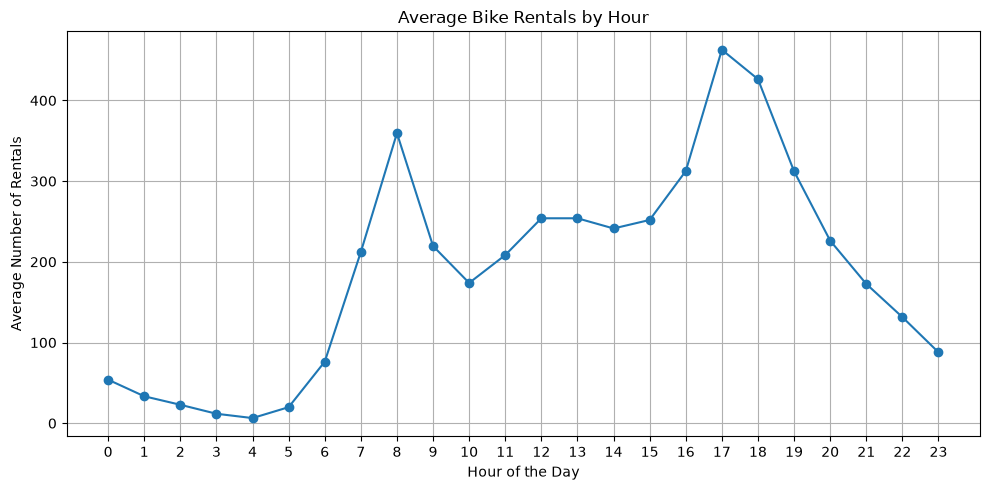

In [14]:
hourly = df.groupby('hr')['cnt'].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly.index, hourly.values, marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

Step 13: Average rentals by season

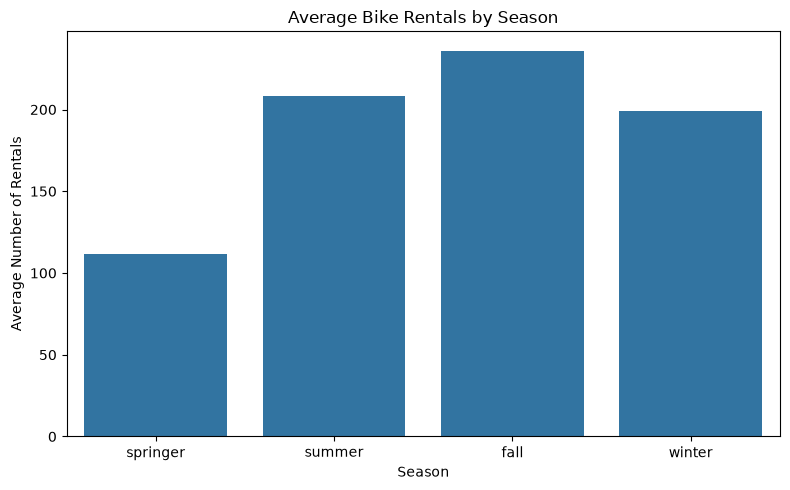

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='season', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Number of Rentals')
plt.tight_layout()
plt.show()

Step 14: Average rentals by weather

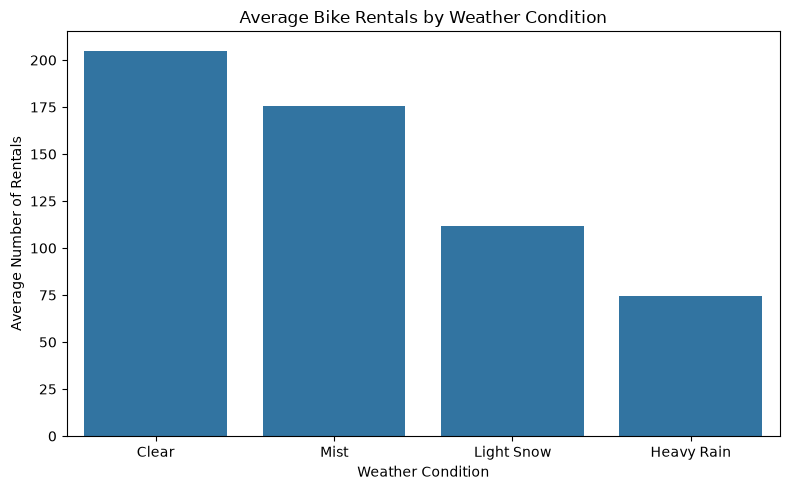

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='weathersit', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Number of Rentals')
plt.tight_layout()
plt.show()

Step 15: Distribution of rentals

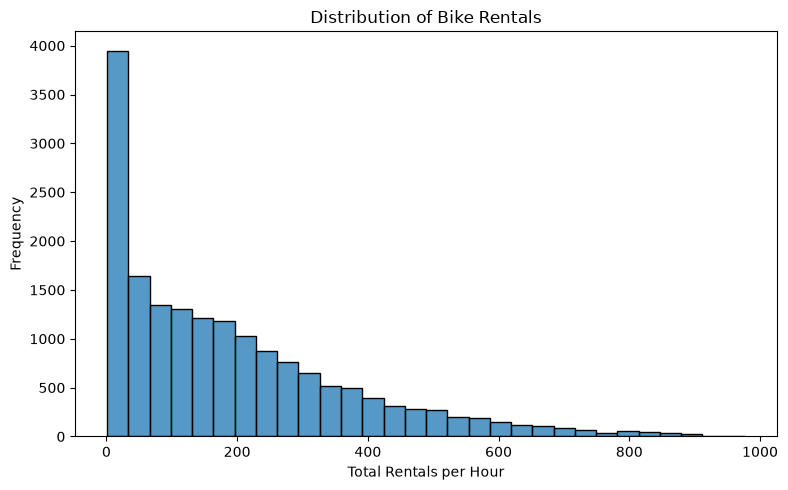

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='cnt', bins=30)

plt.title('Distribution of Bike Rentals')
plt.xlabel('Total Rentals per Hour')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Step 16: Correlation heatmap

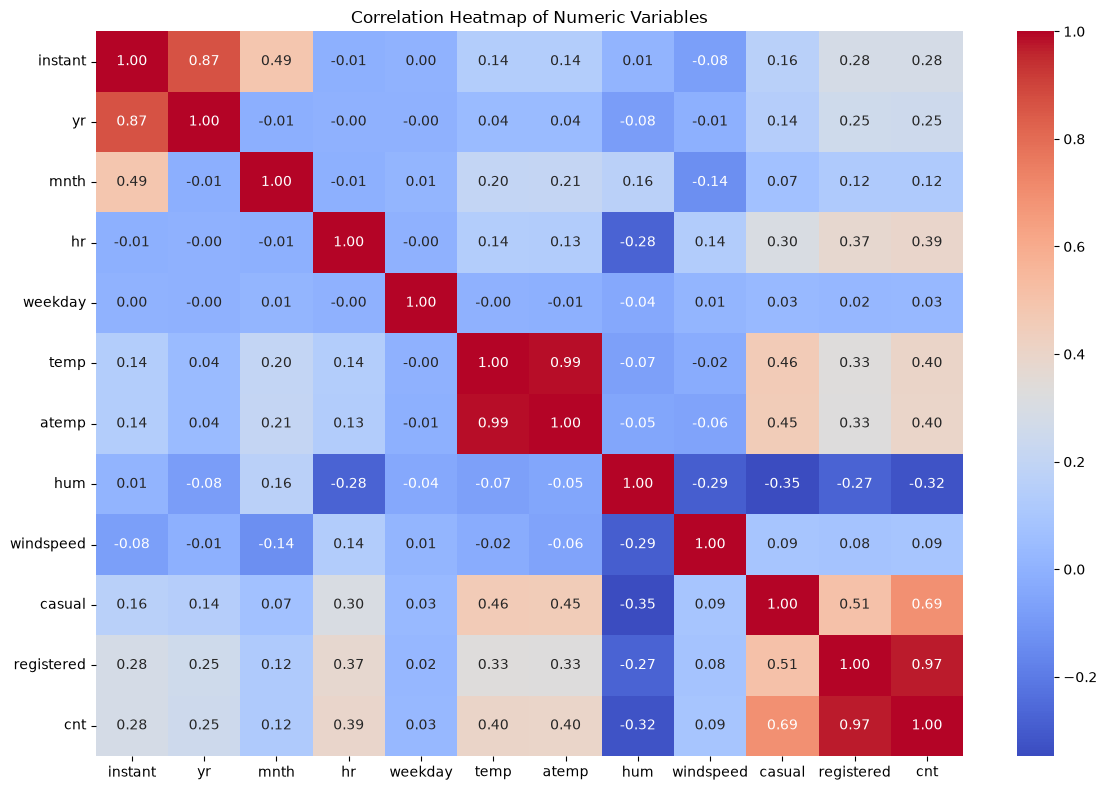

In [18]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.show()

Step 17: Prepare the date column

In [19]:
df['dteday'] = pd.to_datetime(df['dteday'], errors='coerce')
df = df.dropna(subset=['dteday']).copy()

Line 1: Convert the date into a proper date format            
Line 2: Remove rows with invalid dates

Step 18: Daily rentals over time

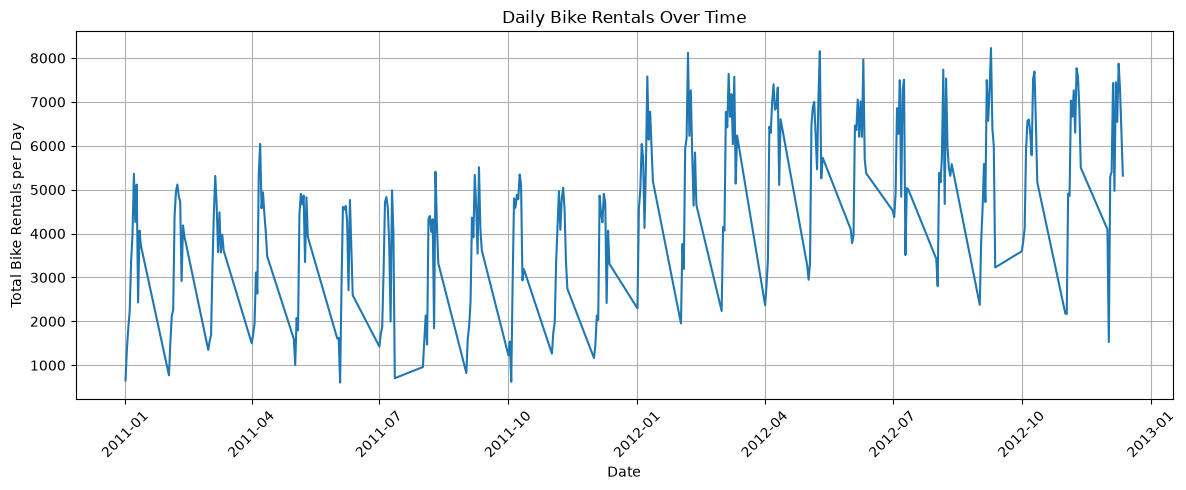

In [21]:
daily_rentals = df.groupby('dteday')['cnt'].sum().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_rentals.index, daily_rentals.values)

plt.title('Daily Bike Rentals Over Time')
plt.xlabel('Date')
plt.ylabel('Total Bike Rentals per Day')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Step 19: Final checks

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 6867 entries, 0 to 16924
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     6867 non-null   int64         
 1   dteday      6867 non-null   datetime64[us]
 2   season      6867 non-null   str           
 3   yr          6867 non-null   float64       
 4   mnth        6867 non-null   float64       
 5   hr          6867 non-null   int64         
 6   holiday     6867 non-null   str           
 7   weekday     6867 non-null   int64         
 8   workingday  6867 non-null   str           
 9   weathersit  6867 non-null   str           
 10  temp        6867 non-null   float64       
 11  atemp       6867 non-null   float64       
 12  hum         6867 non-null   float64       
 13  windspeed   6867 non-null   float64       
 14  casual      6867 non-null   float64       
 15  registered  6867 non-null   float64       
 16  cnt         6867 non-null   int64      

In [23]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [24]:
df.shape

(6867, 17)

Part 1 and Part 2 cover understanding and cleaning the data; Part 3 covers visual EDA and time-series analysis.